# Rare Trials Analysis

This notebook starts the rare-trial analysis figure. The first two GridSpec panels show performance aligned to rare trials in short blocks and long blocks, using two trials before and two trials after the rare trial while staying inside the same contiguous block. The second row summarizes pre-rare, rare, and post-rare performance with strict same-block filtering. Early/late analyses use fixed windows: first 7 trials of a block are early, and the last 7 non-overlapping trials are late.

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec


plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42
plt.rcParams["text.usetex"] = False
plt.rcParams["savefig.dpi"] = 600

DATA_PATH = "/home/ihsan/Desktop/data/Georgia_Tech/2AFC/Codes/Behavior/New_version/all_subjects_final_data.csv"
OUTPUT_PATH = "/home/ihsan/Desktop/data/Georgia_Tech/2AFC/Figures_behavior/Mega_pdf/rare_trials_analysis.pdf"
EXCLUDE_WARMUP = True
OFFSETS = np.arange(-2, 3)
EARLY_LATE_WINDOW = 7
TRANSITION_TRIAL_RANGE = 20
TRANSITION_OFFSETS = np.arange(-TRANSITION_TRIAL_RANGE, TRANSITION_TRIAL_RANGE + 1)
PHASE_ORDER = ["pre_rare", "rare", "post_rare"]
PHASE_LABELS = ["Pre rare", "Rare", "Post rare"]
EPOCH_ORDER = ["early", "late"]
SHORT_EPOCH_COLORS = {"early": "#8ecae6", "late": "#1261a0"}
LONG_EPOCH_COLORS = {"early": "#f4a3a3", "late": "#b11226"}

# Use "event" for SEM across rare-aligned events, or "session" for SEM across sessions.
SEM_UNIT = "event"

CORRECT_OUTCOMES = {"Reward", "RewardNaive", "ChangingMindReward"}
INCORRECT_OUTCOMES = {"Punish", "PunishNaive"}


def clean_axis(ax):
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


def require_columns(df, columns):
    missing = [column for column in columns if column not in df.columns]
    if missing:
        raise ValueError(f"Missing required column(s): {', '.join(missing)}")


def add_session_key(df):
    df = df.copy()
    if "session_uid" in df.columns:
        df["session_key"] = df["session_uid"].astype(str)
    elif {"subject", "session_idx"}.issubset(df.columns):
        df["session_key"] = df["subject"].astype(str) + "_S" + df["session_idx"].astype(str)
    elif "session_idx" in df.columns:
        df["session_key"] = "S" + df["session_idx"].astype(str)
    else:
        df["session_key"] = "S1"
    return df


def prepare_dataframe(path):
    df = pd.read_csv(path).copy()
    require_columns(df, ["outcome", "trial_type", "block_type"])

    df["_source_row"] = np.arange(len(df))
    for column in ["trial_type", "block_type", "warm_up"]:
        if column in df.columns:
            df[column] = pd.to_numeric(df[column], errors="coerce")

    if EXCLUDE_WARMUP and "warm_up" in df.columns:
        df = df[df["warm_up"].fillna(0).eq(0)].copy()

    df = df.dropna(subset=["trial_type", "block_type"]).copy()
    df["trial_type"] = df["trial_type"].astype(int)
    df["block_type"] = df["block_type"].astype(int)
    df = add_session_key(df)
    df = df.sort_values(["session_key", "_source_row"]).reset_index(drop=True)

    outcome = df["outcome"].astype(str)
    df["correct"] = np.nan
    df.loc[outcome.isin(CORRECT_OUTCOMES), "correct"] = 1.0
    df.loc[outcome.isin(INCORRECT_OUTCOMES), "correct"] = 0.0

    choice = df["lick_side"].astype(str).str.strip().str.lower() if "lick_side" in df.columns else pd.Series("", index=df.index)
    if "Contingency_idx" in df.columns:
        contingency_idx = pd.to_numeric(df["Contingency_idx"], errors="coerce")
        normal_contingency = contingency_idx.eq(1)
        reverse_contingency = contingency_idx.eq(2)
    elif "Contingency" in df.columns:
        contingency = df["Contingency"].astype(str)
        normal_contingency = contingency.str.contains("Normal - Short/Left", na=False)
        reverse_contingency = contingency.str.contains("Reverse - Long/Left", na=False)
    else:
        normal_contingency = pd.Series(True, index=df.index)
        reverse_contingency = pd.Series(False, index=df.index)

    df["choose_long"] = np.nan
    valid_choice = choice.isin(["left", "right"])
    df.loc[valid_choice & normal_contingency, "choose_long"] = choice[valid_choice & normal_contingency].eq("right").astype(float)
    df.loc[valid_choice & reverse_contingency, "choose_long"] = choice[valid_choice & reverse_contingency].eq("left").astype(float)
    df["choose_short"] = 1.0 - df["choose_long"]

    # In this task, rare means long trials in short blocks or short trials in long blocks.
    df["is_rare"] = False
    df.loc[df["block_type"].eq(1) & df["trial_type"].eq(2), "is_rare"] = True
    df.loc[df["block_type"].eq(2) & df["trial_type"].eq(1), "is_rare"] = True

    df["_trial_order"] = df.groupby("session_key", sort=False).cumcount() + 1
    df["block_instance"] = df.groupby("session_key", sort=False)["block_type"].transform(
        lambda values: values.ne(values.shift()).cumsum()
    )
    df["_within_block_index"] = df.groupby(
        ["session_key", "block_instance"], sort=False
    ).cumcount()
    df["_block_length"] = df.groupby(
        ["session_key", "block_instance"], sort=False
    )["block_type"].transform("size")
    df["block_epoch"] = "middle"
    early_mask = df["_within_block_index"].lt(EARLY_LATE_WINDOW)
    late_mask = df["_within_block_index"].ge(df["_block_length"] - EARLY_LATE_WINDOW) & ~early_mask
    df.loc[early_mask, "block_epoch"] = "early"
    df.loc[late_mask, "block_epoch"] = "late"

    return df


def collect_aligned_rare_trials(df, anchor_block_type, offsets=OFFSETS):
    anchor_mask = df["is_rare"] & df["block_type"].eq(anchor_block_type)
    anchors = df.loc[anchor_mask].copy()

    block_lookup = {}
    for key, block_df in df.groupby(["session_key", "block_instance"], sort=False):
        block_lookup[key] = block_df.set_index("_within_block_index", drop=False)

    rows = []
    for anchor_index, anchor in anchors.iterrows():
        key = (anchor["session_key"], anchor["block_instance"])
        block_df = block_lookup[key]
        anchor_position = int(anchor["_within_block_index"])
        anchor_id = f"{anchor['session_key']}_{anchor_index}"

        for offset in offsets:
            target_position = anchor_position + int(offset)
            if target_position not in block_df.index:
                continue

            trial = block_df.loc[target_position]
            rows.append(
                {
                    "anchor_id": anchor_id,
                    "anchor_session": anchor["session_key"],
                    "anchor_trial_order": int(anchor["_trial_order"]),
                    "anchor_block_type": int(anchor_block_type),
                    "anchor_epoch": anchor["block_epoch"],
                    "offset": int(offset),
                    "target_trial_order": int(trial["_trial_order"]),
                    "target_trial_type": int(trial["trial_type"]),
                    "target_block_type": int(trial["block_type"]),
                    "target_is_rare": bool(trial["is_rare"]),
                    "outcome": trial["outcome"],
                    "correct": trial["correct"],
                }
            )

    return pd.DataFrame(rows)


def summarize_aligned(aligned, offsets=OFFSETS, sem_unit=SEM_UNIT):
    if aligned.empty:
        return pd.DataFrame(
            {
                "offset": offsets,
                "mean": np.nan,
                "sem": np.nan,
                "n": 0,
                "rare_rate": np.nan,
                "rare_n": 0,
                "rare_total": 0,
            }
        )

    rare_stats = (
        aligned.groupby("offset")["target_is_rare"]
        .agg(rare_rate="mean", rare_n="sum", rare_total="count")
        .reset_index()
    )

    data = aligned.dropna(subset=["correct"]).copy()
    if data.empty:
        summary = pd.DataFrame({"offset": offsets, "mean": np.nan, "sem": np.nan, "n": 0})
        summary = summary.merge(rare_stats, on="offset", how="left")
        summary[["rare_n", "rare_total"]] = summary[["rare_n", "rare_total"]].fillna(0).astype(int)
        return summary

    if sem_unit == "session":
        data = (
            data.groupby(["offset", "anchor_session"], as_index=False)["correct"]
            .mean()
            .rename(columns={"correct": "unit_correct"})
        )
        grouped = data.groupby("offset")["unit_correct"]
    elif sem_unit == "event":
        grouped = data.groupby("offset")["correct"]
    else:
        raise ValueError("SEM_UNIT must be 'event' or 'session'.")

    summary = grouped.agg(mean="mean", sem="sem", n="count").reset_index()
    summary = pd.DataFrame({"offset": offsets}).merge(summary, on="offset", how="left")
    summary = summary.merge(rare_stats, on="offset", how="left")
    summary["n"] = summary["n"].fillna(0).astype(int)
    summary[["rare_n", "rare_total"]] = summary[["rare_n", "rare_total"]].fillna(0).astype(int)
    summary.loc[summary["n"].le(1), "sem"] = 0.0
    return summary


def summarize_aligned_by_epoch(aligned, offsets=OFFSETS, sem_unit=SEM_UNIT):
    base = pd.MultiIndex.from_product(
        [offsets, EPOCH_ORDER], names=["offset", "anchor_epoch"]
    ).to_frame(index=False)
    if aligned.empty:
        return base.assign(mean=np.nan, sem=np.nan, n=0)

    data = aligned.dropna(subset=["correct"]).copy()
    if data.empty:
        return base.assign(mean=np.nan, sem=np.nan, n=0)

    if sem_unit == "session":
        data = (
            data.groupby(["offset", "anchor_epoch", "anchor_session"], as_index=False)["correct"]
            .mean()
            .rename(columns={"correct": "unit_correct"})
        )
        grouped = data.groupby(["offset", "anchor_epoch"])["unit_correct"]
    elif sem_unit == "event":
        grouped = data.groupby(["offset", "anchor_epoch"])["correct"]
    else:
        raise ValueError("SEM_UNIT must be 'event' or 'session'.")

    summary = grouped.agg(mean="mean", sem="sem", n="count").reset_index()
    summary = base.merge(summary, on=["offset", "anchor_epoch"], how="left")
    summary["n"] = summary["n"].fillna(0).astype(int)
    summary.loc[summary["n"].le(1), "sem"] = 0.0
    return summary


def plot_aligned_performance(ax, summary, title, color):
    ax.errorbar(
        summary["offset"],
        summary["mean"],
        yerr=summary["sem"],
        marker="o",
        linewidth=2,
        capsize=4,
        color=color,
    )
    ax.axvline(0, color="black", linestyle="--", linewidth=1, alpha=0.35)
    ax.axhline(0.5, color="black", linestyle=":", linewidth=1, alpha=0.35)
    ax.set_title(title)
    ax.set_xlabel("Trial aligned to rare trial")
    ax.set_ylabel("Performance (fraction correct)")
    ax.set_xticks(OFFSETS)
    ax.set_xticklabels(["-2", "-1", "Rare", "+1", "+2"])

    for _, row in summary.iterrows():
        if row["n"] > 0:
            ax.text(row["offset"], 0.03, f"n={int(row['n'])}", ha="center", va="bottom", fontsize=8)

    clean_axis(ax)

    rate_ax = ax.twinx()
    rate_ax.plot(
        summary["offset"],
        summary["rare_rate"],
        color="0.45",
        linestyle="--",
        linewidth=1.8,
    )
    rate_ax.set_ylabel("Rare trial rate", color="0.35")
    rate_ax.set_ylim(-0.02, 1.02)
    rate_ax.tick_params(axis="y", colors="0.35")
    rate_ax.grid(False)
    rate_ax.spines["top"].set_visible(False)
    rate_ax.spines["right"].set_color("0.35")

    return rate_ax


def plot_aligned_epoch_performance(ax, summary, title, colors):
    for epoch in EPOCH_ORDER:
        epoch_data = summary[summary["anchor_epoch"].eq(epoch)].copy()
        ax.errorbar(
            epoch_data["offset"],
            epoch_data["mean"],
            yerr=epoch_data["sem"],
            marker="o",
            linewidth=2,
            capsize=4,
            color=colors[epoch],
            label=epoch.capitalize(),
        )

    ax.axvline(0, color="black", linestyle="--", linewidth=1, alpha=0.35)
    ax.axhline(0.5, color="black", linestyle=":", linewidth=1, alpha=0.35)
    ax.set_title(title)
    ax.set_xlabel("Trial aligned to rare trial")
    ax.set_ylabel("Performance (fraction correct)")
    ax.set_xticks(OFFSETS)
    ax.set_xticklabels(["-2", "-1", "Rare", "+1", "+2"])
    ax.legend(frameon=False, fontsize=8)
    clean_axis(ax)


def collect_pre_rare_post_trials(df, anchor_block_type):
    anchor_mask = df["is_rare"] & df["block_type"].eq(anchor_block_type)
    anchors = df.loc[anchor_mask].copy()

    block_lookup = {}
    for key, block_df in df.groupby(["session_key", "block_instance"], sort=False):
        block_lookup[key] = block_df.set_index("_within_block_index", drop=False)

    def add_phase_row(rows, anchor, anchor_index, phase, phase_order, trial):
        rows.append(
            {
                "anchor_id": f"{anchor['session_key']}_{anchor_index}",
                "anchor_session": anchor["session_key"],
                "anchor_trial_order": int(anchor["_trial_order"]),
                "anchor_block_type": int(anchor_block_type),
                "anchor_epoch": anchor["block_epoch"],
                "phase": phase,
                "phase_order": phase_order,
                "target_trial_order": int(trial["_trial_order"]),
                "target_trial_type": int(trial["trial_type"]),
                "target_block_type": int(trial["block_type"]),
                "target_is_rare": bool(trial["is_rare"]),
                "outcome": trial["outcome"],
                "correct": trial["correct"],
            }
        )

    rows = []
    for anchor_index, anchor in anchors.iterrows():
        key = (anchor["session_key"], anchor["block_instance"])
        block_df = block_lookup[key]
        anchor_position = int(anchor["_within_block_index"])

        pre_position = anchor_position - 1
        post_position = anchor_position + 1
        if pre_position not in block_df.index or post_position not in block_df.index:
            continue

        pre_trial = block_df.loc[pre_position]
        post_trial = block_df.loc[post_position]
        previous_position = pre_position - 1
        pre_is_after_rare = (
            previous_position in block_df.index
            and bool(block_df.loc[previous_position, "is_rare"])
        )
        sequence_matches_rules = (
            not bool(pre_trial["is_rare"])
            and not pre_is_after_rare
            and not bool(post_trial["is_rare"])
        )
        if not sequence_matches_rules:
            continue

        add_phase_row(rows, anchor, anchor_index, "pre_rare", 0, pre_trial)
        add_phase_row(rows, anchor, anchor_index, "rare", 1, anchor)
        add_phase_row(rows, anchor, anchor_index, "post_rare", 2, post_trial)

    return pd.DataFrame(rows)


def summarize_phase_performance(phase_data, sem_unit=SEM_UNIT):
    base = pd.DataFrame({"phase": PHASE_ORDER, "phase_order": range(len(PHASE_ORDER))})
    if phase_data.empty:
        base["mean"] = np.nan
        base["sem"] = np.nan
        base["n"] = 0
        return base

    data = phase_data.dropna(subset=["correct"]).copy()
    if data.empty:
        base["mean"] = np.nan
        base["sem"] = np.nan
        base["n"] = 0
        return base

    if sem_unit == "session":
        data = (
            data.groupby(["phase", "phase_order", "anchor_session"], as_index=False)["correct"]
            .mean()
            .rename(columns={"correct": "unit_correct"})
        )
        grouped = data.groupby(["phase", "phase_order"])["unit_correct"]
    elif sem_unit == "event":
        grouped = data.groupby(["phase", "phase_order"])["correct"]
    else:
        raise ValueError("SEM_UNIT must be 'event' or 'session'.")

    summary = grouped.agg(mean="mean", sem="sem", n="count").reset_index()
    summary = base.merge(summary, on=["phase", "phase_order"], how="left")
    summary["n"] = summary["n"].fillna(0).astype(int)
    summary.loc[summary["n"].le(1), "sem"] = 0.0
    return summary


def summarize_phase_performance_by_epoch(phase_data, sem_unit=SEM_UNIT):
    base = pd.MultiIndex.from_product(
        [PHASE_ORDER, EPOCH_ORDER], names=["phase", "anchor_epoch"]
    ).to_frame(index=False)
    phase_order_map = {phase: idx for idx, phase in enumerate(PHASE_ORDER)}
    base["phase_order"] = base["phase"].map(phase_order_map)

    if phase_data.empty:
        return base.assign(mean=np.nan, sem=np.nan, n=0)

    data = phase_data.dropna(subset=["correct"]).copy()
    if data.empty:
        return base.assign(mean=np.nan, sem=np.nan, n=0)

    if sem_unit == "session":
        data = (
            data.groupby(["phase", "phase_order", "anchor_epoch", "anchor_session"], as_index=False)["correct"]
            .mean()
            .rename(columns={"correct": "unit_correct"})
        )
        grouped = data.groupby(["phase", "phase_order", "anchor_epoch"])["unit_correct"]
    elif sem_unit == "event":
        grouped = data.groupby(["phase", "phase_order", "anchor_epoch"])["correct"]
    else:
        raise ValueError("SEM_UNIT must be 'event' or 'session'.")

    summary = grouped.agg(mean="mean", sem="sem", n="count").reset_index()
    summary = base.merge(summary, on=["phase", "phase_order", "anchor_epoch"], how="left")
    summary["n"] = summary["n"].fillna(0).astype(int)
    summary.loc[summary["n"].le(1), "sem"] = 0.0
    return summary


def plot_phase_performance(ax, summary, title, color):
    ax.errorbar(
        summary["phase_order"],
        summary["mean"],
        yerr=summary["sem"],
        fmt="o",
        linestyle="none",
        markersize=7,
        capsize=5,
        color=color,
    )
    ax.axhline(0.5, color="black", linestyle=":", linewidth=1, alpha=0.35)
    ax.set_title(title)
    ax.set_ylabel("Performance (fraction correct)")
    ax.set_xticks(range(len(PHASE_ORDER)))
    ax.set_xticklabels(PHASE_LABELS)

    for _, row in summary.iterrows():
        if row["n"] > 0:
            ax.text(row["phase_order"], 0.03, f"n={int(row['n'])}", ha="center", va="bottom", fontsize=8)

    clean_axis(ax)


def plot_phase_epoch_performance(ax, summary, title, colors):
    jitter = {"early": -0.08, "late": 0.08}
    for epoch in EPOCH_ORDER:
        epoch_data = summary[summary["anchor_epoch"].eq(epoch)].copy()
        x = epoch_data["phase_order"].to_numpy(dtype=float) + jitter[epoch]
        ax.errorbar(
            x,
            epoch_data["mean"],
            yerr=epoch_data["sem"],
            fmt="o",
            linestyle="none",
            markersize=7,
            capsize=5,
            color=colors[epoch],
            label=epoch.capitalize(),
        )
        label_y = 0.03 if epoch == "early" else 0.09
        for x_value, (_, row) in zip(x, epoch_data.iterrows()):
            if row["n"] > 0:
                ax.text(
                    x_value,
                    label_y,
                    f"n={int(row['n'])}",
                    ha="center",
                    va="bottom",
                    fontsize=7,
                    color=colors[epoch],
                )

    ax.axhline(0.5, color="black", linestyle=":", linewidth=1, alpha=0.35)
    ax.set_title(title)
    ax.set_ylabel("Performance (fraction correct)")
    ax.set_xticks(range(len(PHASE_ORDER)))
    ax.set_xticklabels(PHASE_LABELS)
    ax.legend(frameon=False, fontsize=8)
    clean_axis(ax)


def add_rules_box(ax):
    ax.axis("off")
    rules = (
        "Rules:\n"
        "Complete pre/rare/post triplets only\n"
        "Triplet stays in same block\n"
        "Pre is not rare\n"
        "Pre is not after rare\n"
        "Post is not rare"
    )
    ax.text(
        0.5,
        0.5,
        rules,
        transform=ax.transAxes,
        ha="center",
        va="center",
        fontsize=9,
        bbox={"boxstyle": "round,pad=0.35", "facecolor": "white", "edgecolor": "0.6", "alpha": 0.9},
    )


def collect_transition_trials(df, trans_type, trial_range=TRANSITION_TRIAL_RANGE):
    if trans_type not in {"S2L", "L2S"}:
        raise ValueError("trans_type must be 'S2L' or 'L2S'.")

    rows = []
    transition_counter = 0

    for session_key, sdf in df.groupby("session_key", sort=False):
        sdf = sdf[sdf["block_type"].isin([1, 2])].sort_values("_trial_order").reset_index(drop=True)
        if sdf.empty:
            continue

        block_change = sdf["block_type"].ne(sdf["block_type"].shift())
        transition_indices = sdf.index[block_change & sdf["block_type"].shift().notna()].tolist()

        for transition_index in transition_indices:
            old_block = int(sdf.loc[transition_index - 1, "block_type"])
            new_block = int(sdf.loc[transition_index, "block_type"])
            if trans_type == "S2L" and not (old_block == 1 and new_block == 2):
                continue
            if trans_type == "L2S" and not (old_block == 2 and new_block == 1):
                continue

            transition_counter += 1
            transition_id = f"{trans_type}_{session_key}_{transition_counter}"

            for rel_trial in range(-trial_range, trial_range + 1):
                target_index = transition_index + rel_trial
                if target_index < 0 or target_index >= len(sdf):
                    continue

                trial = sdf.loc[target_index]
                expected_block = old_block if rel_trial < 0 else new_block
                if int(trial["block_type"]) != expected_block:
                    continue

                rows.append(
                    {
                        "transition_id": transition_id,
                        "session_key": session_key,
                        "trans_type": trans_type,
                        "old_block": old_block,
                        "new_block": new_block,
                        "rel_trial": int(rel_trial),
                        "target_trial_order": int(trial["_trial_order"]),
                        "target_trial_type": int(trial["trial_type"]),
                        "target_block_type": int(trial["block_type"]),
                        "target_is_rare": bool(trial["is_rare"]),
                        "outcome": trial["outcome"],
                        "correct": trial["correct"],
                    }
                )

    return pd.DataFrame(rows)


def summarize_transition_trials(transition_data, trial_subset="rare", offsets=TRANSITION_OFFSETS, sem_unit=SEM_UNIT):
    base = pd.DataFrame({"rel_trial": offsets})
    if transition_data.empty:
        return base.assign(mean=np.nan, sem=np.nan, n=0, rare_rate=np.nan, rare_n=0, rare_total=0)
    if trial_subset not in {"all", "rare", "common"}:
        raise ValueError("trial_subset must be 'all', 'rare', or 'common'.")

    rare_stats = (
        transition_data.groupby("rel_trial")["target_is_rare"]
        .agg(rare_rate="mean", rare_n="sum", rare_total="count")
        .reset_index()
    )

    if trial_subset == "rare":
        perf_data = transition_data[transition_data["target_is_rare"]].copy()
    elif trial_subset == "common":
        perf_data = transition_data[~transition_data["target_is_rare"]].copy()
    else:
        perf_data = transition_data.copy()

    perf_data = perf_data.dropna(subset=["correct"]).copy()
    if perf_data.empty:
        summary = base.assign(mean=np.nan, sem=np.nan, n=0)
        summary = summary.merge(rare_stats, on="rel_trial", how="left")
        summary[["rare_n", "rare_total"]] = summary[["rare_n", "rare_total"]].fillna(0).astype(int)
        return summary

    if sem_unit == "session":
        perf_data = (
            perf_data.groupby(["rel_trial", "session_key"], as_index=False)["correct"]
            .mean()
            .rename(columns={"correct": "unit_correct"})
        )
        grouped = perf_data.groupby("rel_trial")["unit_correct"]
    elif sem_unit == "event":
        grouped = perf_data.groupby("rel_trial")["correct"]
    else:
        raise ValueError("SEM_UNIT must be 'event' or 'session'.")

    summary = grouped.agg(mean="mean", sem="sem", n="count").reset_index()
    summary = base.merge(summary, on="rel_trial", how="left")
    summary = summary.merge(rare_stats, on="rel_trial", how="left")
    summary["n"] = summary["n"].fillna(0).astype(int)
    summary[["rare_n", "rare_total"]] = summary[["rare_n", "rare_total"]].fillna(0).astype(int)
    summary.loc[summary["n"].le(1), "sem"] = 0.0
    return summary


def plot_transition_performance(ax, summary, title, color, ylabel="Performance"):
    valid = summary.dropna(subset=["mean"]).copy()
    if not valid.empty:
        ax.plot(
            valid["rel_trial"],
            valid["mean"],
            marker="o",
            linewidth=2,
            markersize=4,
            color=color,
        )
        ax.fill_between(
            valid["rel_trial"].to_numpy(dtype=float),
            (valid["mean"] - valid["sem"]).to_numpy(dtype=float),
            (valid["mean"] + valid["sem"]).to_numpy(dtype=float),
            color=color,
            alpha=0.18,
            linewidth=0,
        )
    else:
        ax.text(0.5, 0.5, "No usable trials", transform=ax.transAxes, ha="center", va="center")

    ax.axvline(0, color="black", linestyle="--", linewidth=1, alpha=0.35)
    ax.axhline(0.5, color="black", linestyle=":", linewidth=1, alpha=0.35)
    ax.set_title(title)
    ax.set_xlabel("Trial aligned to block transition")
    ax.set_ylabel(ylabel)
    ax.set_xlim(TRANSITION_OFFSETS.min(), TRANSITION_OFFSETS.max())
    clean_axis(ax)

    rate_ax = ax.twinx()
    rate_ax.plot(
        summary["rel_trial"],
        summary["rare_rate"],
        color="0.45",
        linestyle="--",
        linewidth=1.8,
    )
    rate_ax.set_ylabel("Rare trial rate", color="0.35")
    rate_ax.set_ylim(-0.02, 1.02)
    rate_ax.tick_params(axis="y", colors="0.35")
    rate_ax.grid(False)
    rate_ax.spines["top"].set_visible(False)
    rate_ax.spines["right"].set_color("0.35")

    return rate_ax


def collect_rare_trial_impact_anchors(df, anchor_block_type, next_lag=1):
    if anchor_block_type not in {1, 2}:
        raise ValueError("anchor_block_type must be 1 for short block or 2 for long block.")

    rows = []
    block_df_all = df[df["block_type"].eq(anchor_block_type)].copy()

    for (session_key, block_instance), block_df in block_df_all.groupby(
        ["session_key", "block_instance"], sort=False
    ):
        block_df = block_df.sort_values("_within_block_index").set_index("_within_block_index", drop=False)

        for anchor_position, anchor in block_df.iterrows():
            next_position = int(anchor_position) + int(next_lag)
            if next_position not in block_df.index:
                continue

            next_trial = block_df.loc[next_position]
            if anchor_block_type == 1:
                next_choice_toward_rare = next_trial["choose_long"]
                rare_category = "long"
            else:
                next_choice_toward_rare = next_trial["choose_short"]
                rare_category = "short"

            rows.append(
                {
                    "session_key": session_key,
                    "block_instance": block_instance,
                    "anchor_block_type": int(anchor_block_type),
                    "anchor_position": int(anchor_position),
                    "anchor_is_rare": bool(anchor["is_rare"]),
                    "anchor_trial_type": int(anchor["trial_type"]),
                    "anchor_trial_order": int(anchor["_trial_order"]),
                    "next_lag": int(next_lag),
                    "next_trial_order": int(next_trial["_trial_order"]),
                    "next_trial_type": int(next_trial["trial_type"]),
                    "next_is_rare": bool(next_trial["is_rare"]),
                    "next_choice_toward_rare": next_choice_toward_rare,
                    "rare_category": rare_category,
                }
            )

    return pd.DataFrame(rows)


def summarize_rare_trial_impact(impact_data):
    columns = [
        "anchor_position",
        "effect",
        "sem",
        "n_sessions",
        "n_matched_next_type_strata",
        "rare_anchor_mean",
        "common_anchor_mean",
        "n_rare_anchors",
        "n_common_anchors",
        "rare_anchor_rate",
    ]
    if impact_data.empty:
        return pd.DataFrame(columns=columns)

    data = impact_data.dropna(subset=["next_choice_toward_rare", "next_trial_type"]).copy()
    if data.empty:
        return pd.DataFrame(columns=columns)

    data["next_trial_type"] = pd.to_numeric(data["next_trial_type"], errors="coerce")
    data = data.dropna(subset=["next_trial_type"]).copy()
    data["next_trial_type"] = data["next_trial_type"].astype(int)
    if data.empty:
        return pd.DataFrame(columns=columns)

    anchor_rate = (
        data.groupby("anchor_position")["anchor_is_rare"]
        .agg(rare_anchor_rate="mean")
        .reset_index()
    )

    matched_means = (
        data.groupby(["anchor_position", "session_key", "next_trial_type", "anchor_is_rare"])["next_choice_toward_rare"]
        .agg(mean="mean", n="count")
        .reset_index()
    )
    matched_wide = matched_means.pivot(
        index=["anchor_position", "session_key", "next_trial_type"],
        columns="anchor_is_rare",
        values=["mean", "n"],
    )
    matched_wide.columns = [
        f"{metric}_{'rare' if is_rare else 'common'}"
        for metric, is_rare in matched_wide.columns
    ]
    matched_wide = matched_wide.reset_index()

    required = ["mean_common", "mean_rare", "n_common", "n_rare"]
    missing = [column for column in required if column not in matched_wide.columns]
    if missing:
        return pd.DataFrame(columns=columns)

    matched_wide = matched_wide.dropna(subset=["mean_common", "mean_rare"]).copy()
    if matched_wide.empty:
        return pd.DataFrame(columns=columns)

    matched_wide["effect"] = matched_wide["mean_rare"] - matched_wide["mean_common"]

    # Average next-stimulus-matched contrasts within session first, so SEM remains across sessions.
    session_effect = (
        matched_wide.groupby(["anchor_position", "session_key"])["effect"]
        .mean()
        .reset_index()
    )
    effect_summary = (
        session_effect.groupby("anchor_position")["effect"]
        .agg(effect="mean", sem="sem", n_sessions="count")
        .reset_index()
    )
    effect_summary.loc[effect_summary["n_sessions"].le(1), "sem"] = 0.0

    matched_counts = (
        matched_wide.groupby("anchor_position")
        .agg(
            n_matched_next_type_strata=("effect", "count"),
            rare_anchor_mean=("mean_rare", "mean"),
            common_anchor_mean=("mean_common", "mean"),
            n_rare_anchors=("n_rare", "sum"),
            n_common_anchors=("n_common", "sum"),
        )
        .reset_index()
    )

    summary = effect_summary.merge(matched_counts, on="anchor_position", how="left")
    summary = summary.merge(anchor_rate, on="anchor_position", how="left")
    for column in ["n_sessions", "n_matched_next_type_strata", "n_rare_anchors", "n_common_anchors"]:
        if column in summary.columns:
            summary[column] = summary[column].fillna(0).astype(int)

    return summary[columns].sort_values("anchor_position")


def plot_rare_trial_impact(ax, summary, title, color):
    valid = summary.dropna(subset=["effect"]).copy()
    if not valid.empty:
        ax.plot(
            valid["anchor_position"],
            valid["effect"],
            marker="o",
            linewidth=2,
            markersize=4,
            color=color,
        )
        ax.fill_between(
            valid["anchor_position"].to_numpy(dtype=float),
            (valid["effect"] - valid["sem"]).to_numpy(dtype=float),
            (valid["effect"] + valid["sem"]).to_numpy(dtype=float),
            color=color,
            alpha=0.18,
            linewidth=0,
        )
    else:
        ax.text(0.5, 0.5, "No matched anchors", transform=ax.transAxes, ha="center", va="center")

    ax.axhline(0, color="black", linestyle="--", linewidth=1, alpha=0.45)
    ax.set_title(title)
    ax.set_xlabel("Anchor trial position from block onset (k)")
    ax.set_ylabel("Δ next choice toward rare category")
    clean_axis(ax)

    rate_ax = ax.twinx()
    rate_ax.plot(
        summary["anchor_position"],
        summary["rare_anchor_rate"],
        color="0.45",
        linestyle="--",
        linewidth=1.8,
    )
    rate_ax.set_ylabel("Rare anchor rate", color="0.35")
    rate_ax.set_ylim(-0.02, 1.02)
    rate_ax.tick_params(axis="y", colors="0.35")
    rate_ax.grid(False)
    rate_ax.spines["top"].set_visible(False)
    rate_ax.spines["right"].set_color("0.35")

    return rate_ax


def make_rare_trials_figure(df):
    aligned_short = collect_aligned_rare_trials(df, anchor_block_type=1)
    aligned_long = collect_aligned_rare_trials(df, anchor_block_type=2)
    phase_short = collect_pre_rare_post_trials(df, anchor_block_type=1)
    phase_long = collect_pre_rare_post_trials(df, anchor_block_type=2)
    transition_s2l = collect_transition_trials(df, trans_type="S2L")
    transition_l2s = collect_transition_trials(df, trans_type="L2S")
    impact_short = collect_rare_trial_impact_anchors(df, anchor_block_type=1, next_lag=1)
    impact_long = collect_rare_trial_impact_anchors(df, anchor_block_type=2, next_lag=1)

    summary_short = summarize_aligned(aligned_short)
    summary_long = summarize_aligned(aligned_long)
    phase_summary_short = summarize_phase_performance(phase_short)
    phase_summary_long = summarize_phase_performance(phase_long)
    aligned_epoch_summary_short = summarize_aligned_by_epoch(aligned_short)
    aligned_epoch_summary_long = summarize_aligned_by_epoch(aligned_long)
    phase_epoch_summary_short = summarize_phase_performance_by_epoch(phase_short)
    phase_epoch_summary_long = summarize_phase_performance_by_epoch(phase_long)

    transition_summary_all_s2l = summarize_transition_trials(transition_s2l, trial_subset="all")
    transition_summary_all_l2s = summarize_transition_trials(transition_l2s, trial_subset="all")
    transition_summary_rare_s2l = summarize_transition_trials(transition_s2l, trial_subset="rare")
    transition_summary_rare_l2s = summarize_transition_trials(transition_l2s, trial_subset="rare")
    transition_summary_common_s2l = summarize_transition_trials(transition_s2l, trial_subset="common")
    transition_summary_common_l2s = summarize_transition_trials(transition_l2s, trial_subset="common")
    impact_summary_short = summarize_rare_trial_impact(impact_short)
    impact_summary_long = summarize_rare_trial_impact(impact_long)

    n_s2l = transition_s2l["transition_id"].nunique() if not transition_s2l.empty else 0
    n_l2s = transition_l2s["transition_id"].nunique() if not transition_l2s.empty else 0

    fig = plt.figure(figsize=(14, 27))
    gs = gridspec.GridSpec(
        9,
        2,
        figure=fig,
        wspace=0.35,
        hspace=0.75,
        height_ratios=[1.1, 0.16, 1.1, 1.1, 1.1, 1.1, 1.1, 1.1, 1.1],
    )

    ax_short = fig.add_subplot(gs[0, 0])
    ax_long = fig.add_subplot(gs[0, 1])
    ax_rules = fig.add_subplot(gs[1, :])
    ax_phase_short = fig.add_subplot(gs[2, 0])
    ax_phase_long = fig.add_subplot(gs[2, 1])
    ax_transition_all_s2l = fig.add_subplot(gs[3, 0])
    ax_transition_all_l2s = fig.add_subplot(gs[3, 1])
    ax_transition_rare_s2l = fig.add_subplot(gs[4, 0])
    ax_transition_rare_l2s = fig.add_subplot(gs[4, 1])
    ax_transition_common_s2l = fig.add_subplot(gs[5, 0])
    ax_transition_common_l2s = fig.add_subplot(gs[5, 1])
    ax_aligned_epoch_short = fig.add_subplot(gs[6, 0])
    ax_aligned_epoch_long = fig.add_subplot(gs[6, 1])
    ax_phase_epoch_short = fig.add_subplot(gs[7, 0])
    ax_phase_epoch_long = fig.add_subplot(gs[7, 1])
    ax_impact_short = fig.add_subplot(gs[8, 0])
    ax_impact_long = fig.add_subplot(gs[8, 1])

    rate_ax_short = plot_aligned_performance(
        ax_short,
        summary_short,
        "Rare Trials in Short Block",
        color="tab:blue",
    )
    rate_ax_long = plot_aligned_performance(
        ax_long,
        summary_long,
        "Rare Trials in Long Block",
        color="tab:red",
    )
    add_rules_box(ax_rules)

    plot_phase_performance(
        ax_phase_short,
        phase_summary_short,
        "Pre/Rare/Post: Short Block Rare Trials",
        color="tab:blue",
    )
    plot_phase_performance(
        ax_phase_long,
        phase_summary_long,
        "Pre/Rare/Post: Long Block Rare Trials",
        color="tab:red",
    )

    rate_ax_transition_all_s2l = plot_transition_performance(
        ax_transition_all_s2l,
        transition_summary_all_s2l,
        f"Short to Long Transition: All Trials (n={n_s2l} transitions)",
        color="0.2",
        ylabel="All-trial performance",
    )
    rate_ax_transition_all_l2s = plot_transition_performance(
        ax_transition_all_l2s,
        transition_summary_all_l2s,
        f"Long to Short Transition: All Trials (n={n_l2s} transitions)",
        color="0.2",
        ylabel="All-trial performance",
    )
    rate_ax_transition_rare_s2l = plot_transition_performance(
        ax_transition_rare_s2l,
        transition_summary_rare_s2l,
        f"Short to Long Transition: Rare Trials (n={n_s2l} transitions)",
        color="tab:purple",
        ylabel="Rare-trial performance",
    )
    rate_ax_transition_rare_l2s = plot_transition_performance(
        ax_transition_rare_l2s,
        transition_summary_rare_l2s,
        f"Long to Short Transition: Rare Trials (n={n_l2s} transitions)",
        color="tab:green",
        ylabel="Rare-trial performance",
    )
    rate_ax_transition_common_s2l = plot_transition_performance(
        ax_transition_common_s2l,
        transition_summary_common_s2l,
        f"Short to Long Transition: Common Trials (n={n_s2l} transitions)",
        color="tab:orange",
        ylabel="Common-trial performance",
    )
    rate_ax_transition_common_l2s = plot_transition_performance(
        ax_transition_common_l2s,
        transition_summary_common_l2s,
        f"Long to Short Transition: Common Trials (n={n_l2s} transitions)",
        color="tab:olive",
        ylabel="Common-trial performance",
    )

    plot_aligned_epoch_performance(
        ax_aligned_epoch_short,
        aligned_epoch_summary_short,
        "Rare Trials in Short Block: Early vs Late",
        colors=SHORT_EPOCH_COLORS,
    )
    plot_aligned_epoch_performance(
        ax_aligned_epoch_long,
        aligned_epoch_summary_long,
        "Rare Trials in Long Block: Early vs Late",
        colors=LONG_EPOCH_COLORS,
    )
    plot_phase_epoch_performance(
        ax_phase_epoch_short,
        phase_epoch_summary_short,
        "Pre/Rare/Post: Short Block Early vs Late",
        colors=SHORT_EPOCH_COLORS,
    )
    plot_phase_epoch_performance(
        ax_phase_epoch_long,
        phase_epoch_summary_long,
        "Pre/Rare/Post: Long Block Early vs Late",
        colors=LONG_EPOCH_COLORS,
    )
    rate_ax_impact_short = plot_rare_trial_impact(
        ax_impact_short,
        impact_summary_short,
        "Rare-Trial Impact by Block Position: Short Blocks",
        color="tab:blue",
    )
    rate_ax_impact_long = plot_rare_trial_impact(
        ax_impact_long,
        impact_summary_long,
        "Rare-Trial Impact by Block Position: Long Blocks",
        color="tab:red",
    )

    fig.suptitle("Rare-Trial Aligned Performance", y=0.992)
    fig.subplots_adjust(left=0.07, right=0.93, top=0.97, bottom=0.04)

    return {
        "fig": fig,
        "gs": gs,
        "axes": {
            "short_rare": ax_short,
            "long_rare": ax_long,
            "rules": ax_rules,
            "short_rare_phase": ax_phase_short,
            "long_rare_phase": ax_phase_long,
            "transition_all_s2l": ax_transition_all_s2l,
            "transition_all_l2s": ax_transition_all_l2s,
            "transition_rare_s2l": ax_transition_rare_s2l,
            "transition_rare_l2s": ax_transition_rare_l2s,
            "transition_common_s2l": ax_transition_common_s2l,
            "transition_common_l2s": ax_transition_common_l2s,
            "short_rare_epoch": ax_aligned_epoch_short,
            "long_rare_epoch": ax_aligned_epoch_long,
            "short_rare_phase_epoch": ax_phase_epoch_short,
            "long_rare_phase_epoch": ax_phase_epoch_long,
            "impact_short": ax_impact_short,
            "impact_long": ax_impact_long,
        },
        "rate_axes": {
            "short_rare": rate_ax_short,
            "long_rare": rate_ax_long,
            "transition_all_s2l": rate_ax_transition_all_s2l,
            "transition_all_l2s": rate_ax_transition_all_l2s,
            "transition_rare_s2l": rate_ax_transition_rare_s2l,
            "transition_rare_l2s": rate_ax_transition_rare_l2s,
            "transition_common_s2l": rate_ax_transition_common_s2l,
            "transition_common_l2s": rate_ax_transition_common_l2s,
            "impact_short": rate_ax_impact_short,
            "impact_long": rate_ax_impact_long,
        },
        "aligned": {"short_rare": aligned_short, "long_rare": aligned_long},
        "phase_data": {"short_rare": phase_short, "long_rare": phase_long},
        "transition_data": {"S2L": transition_s2l, "L2S": transition_l2s},
        "impact_data": {"short": impact_short, "long": impact_long},
        "summary": {
            "short_rare": summary_short,
            "long_rare": summary_long,
            "short_rare_phase": phase_summary_short,
            "long_rare_phase": phase_summary_long,
            "short_rare_epoch": aligned_epoch_summary_short,
            "long_rare_epoch": aligned_epoch_summary_long,
            "short_rare_phase_epoch": phase_epoch_summary_short,
            "long_rare_phase_epoch": phase_epoch_summary_long,
            "transition_all_s2l": transition_summary_all_s2l,
            "transition_all_l2s": transition_summary_all_l2s,
            "transition_rare_s2l": transition_summary_rare_s2l,
            "transition_rare_l2s": transition_summary_rare_l2s,
            "transition_common_s2l": transition_summary_common_s2l,
            "transition_common_l2s": transition_summary_common_l2s,
            "impact_short": impact_summary_short,
            "impact_long": impact_summary_long,
        },
    }


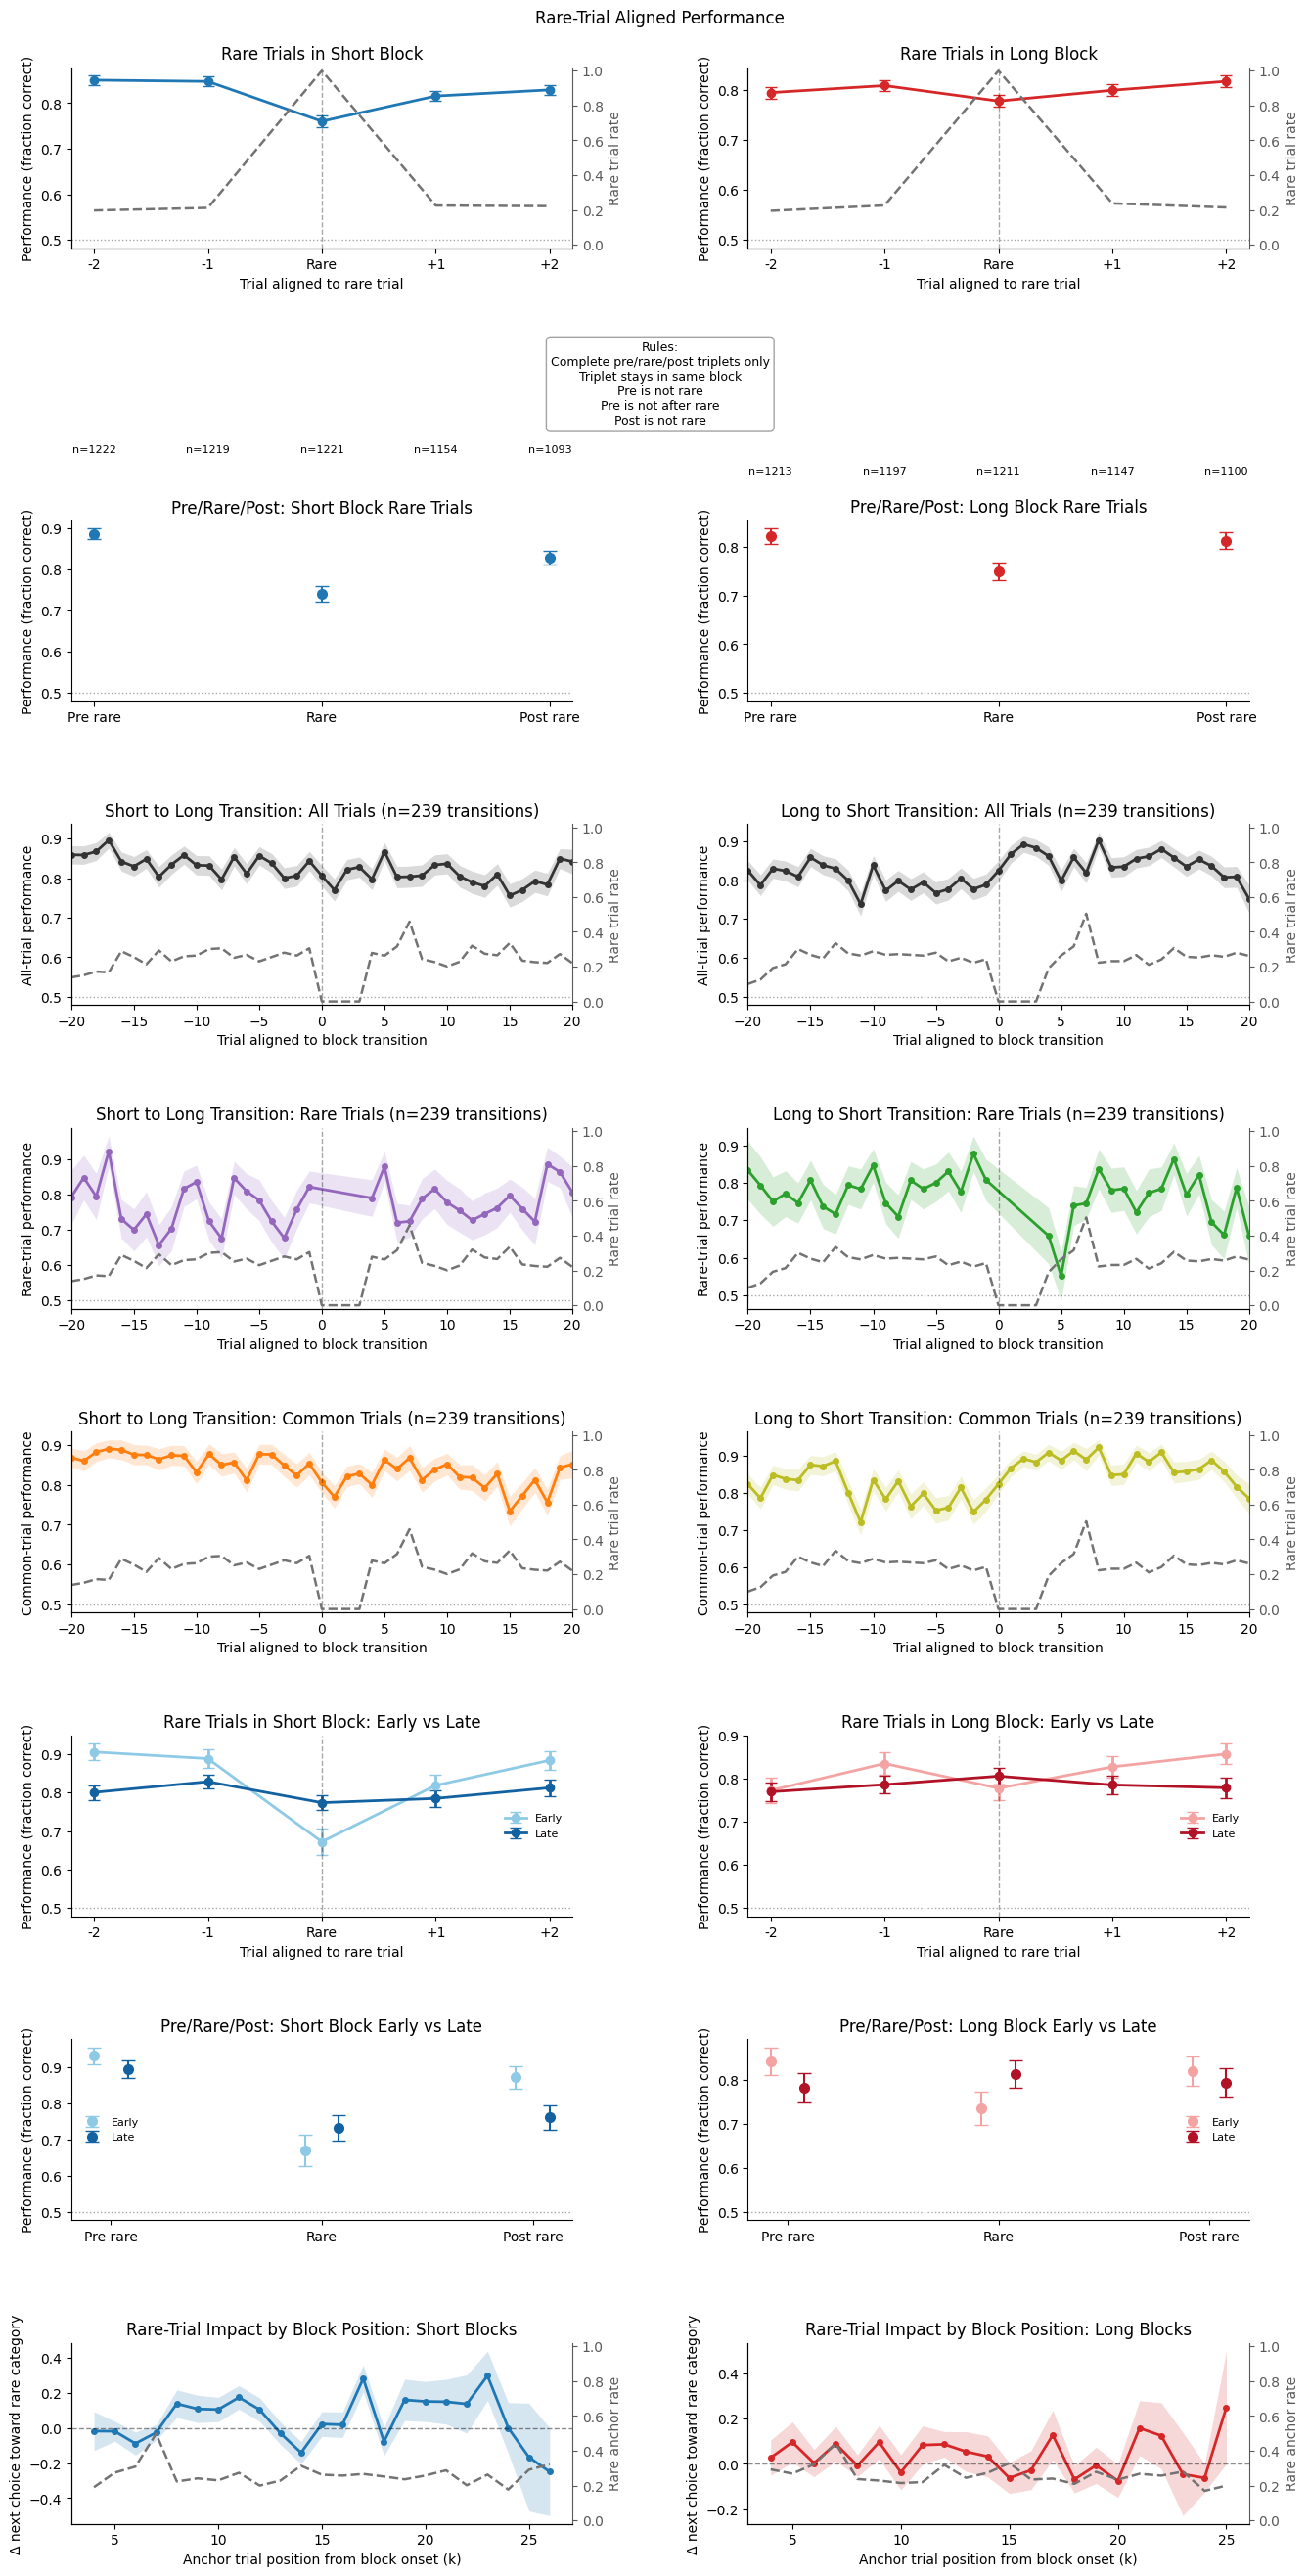

Short-block rare-trial summary
 offset     mean      sem    n  rare_rate  rare_n  rare_total
     -2 0.850245 0.010212 1222   0.196863     251        1275
     -1 0.847416 0.010303 1219   0.211765     270        1275
      0 0.760033 0.012227 1221   1.000000    1275        1275
      1 0.815425 0.011425 1154   0.225188     270        1199
      2 0.828911 0.011396 1093   0.221927     251        1131

Long-block rare-trial summary
 offset     mean      sem    n  rare_rate  rare_n  rare_total
     -2 0.793899 0.011619 1213   0.194876     251        1288
     -1 0.807853 0.011392 1197   0.225932     291        1288
      0 0.777044 0.011966 1211   1.000000    1288        1288
      1 0.798605 0.011847 1147   0.237551     291        1225
      2 0.816364 0.011679 1100   0.214164     251        1172

Short-block pre/rare/post summary
    phase  phase_order     mean      sem   n
 pre_rare            0 0.886165 0.013303 571
     rare            1 0.740351 0.018380 570
post_rare            2 0

In [14]:
df = prepare_dataframe(DATA_PATH)
result = make_rare_trials_figure(df)

result["fig"].savefig(OUTPUT_PATH, dpi=600, bbox_inches="tight")
plt.show()

print("Short-block rare-trial summary")
print(result["summary"]["short_rare"].to_string(index=False))
print("\nLong-block rare-trial summary")
print(result["summary"]["long_rare"].to_string(index=False))
print("\nShort-block pre/rare/post summary")
print(result["summary"]["short_rare_phase"].to_string(index=False))
print("\nLong-block pre/rare/post summary")
print(result["summary"]["long_rare_phase"].to_string(index=False))
print("\nShort-block rare early/late summary")
print(result["summary"]["short_rare_epoch"].dropna(subset=["mean"]).to_string(index=False))
print("\nLong-block rare early/late summary")
print(result["summary"]["long_rare_epoch"].dropna(subset=["mean"]).to_string(index=False))
print("\nShort-block pre/rare/post early/late summary")
print(result["summary"]["short_rare_phase_epoch"].dropna(subset=["mean"]).to_string(index=False))
print("\nLong-block pre/rare/post early/late summary")
print(result["summary"]["long_rare_phase_epoch"].dropna(subset=["mean"]).to_string(index=False))
print("\nShort-to-long transition all-trial summary")
print(result["summary"]["transition_all_s2l"].dropna(subset=["mean"]).to_string(index=False))
print("\nLong-to-short transition all-trial summary")
print(result["summary"]["transition_all_l2s"].dropna(subset=["mean"]).to_string(index=False))
print("\nShort-to-long transition rare-trial summary")
print(result["summary"]["transition_rare_s2l"].dropna(subset=["mean"]).to_string(index=False))
print("\nLong-to-short transition rare-trial summary")
print(result["summary"]["transition_rare_l2s"].dropna(subset=["mean"]).to_string(index=False))
print("\nShort-to-long transition common-trial summary")
print(result["summary"]["transition_common_s2l"].dropna(subset=["mean"]).to_string(index=False))
print("\nLong-to-short transition common-trial summary")
print(result["summary"]["transition_common_l2s"].dropna(subset=["mean"]).to_string(index=False))
print("\nRare-trial impact summary: short blocks")
print(result["summary"]["impact_short"].to_string(index=False))
print("\nRare-trial impact summary: long blocks")
print(result["summary"]["impact_long"].to_string(index=False))


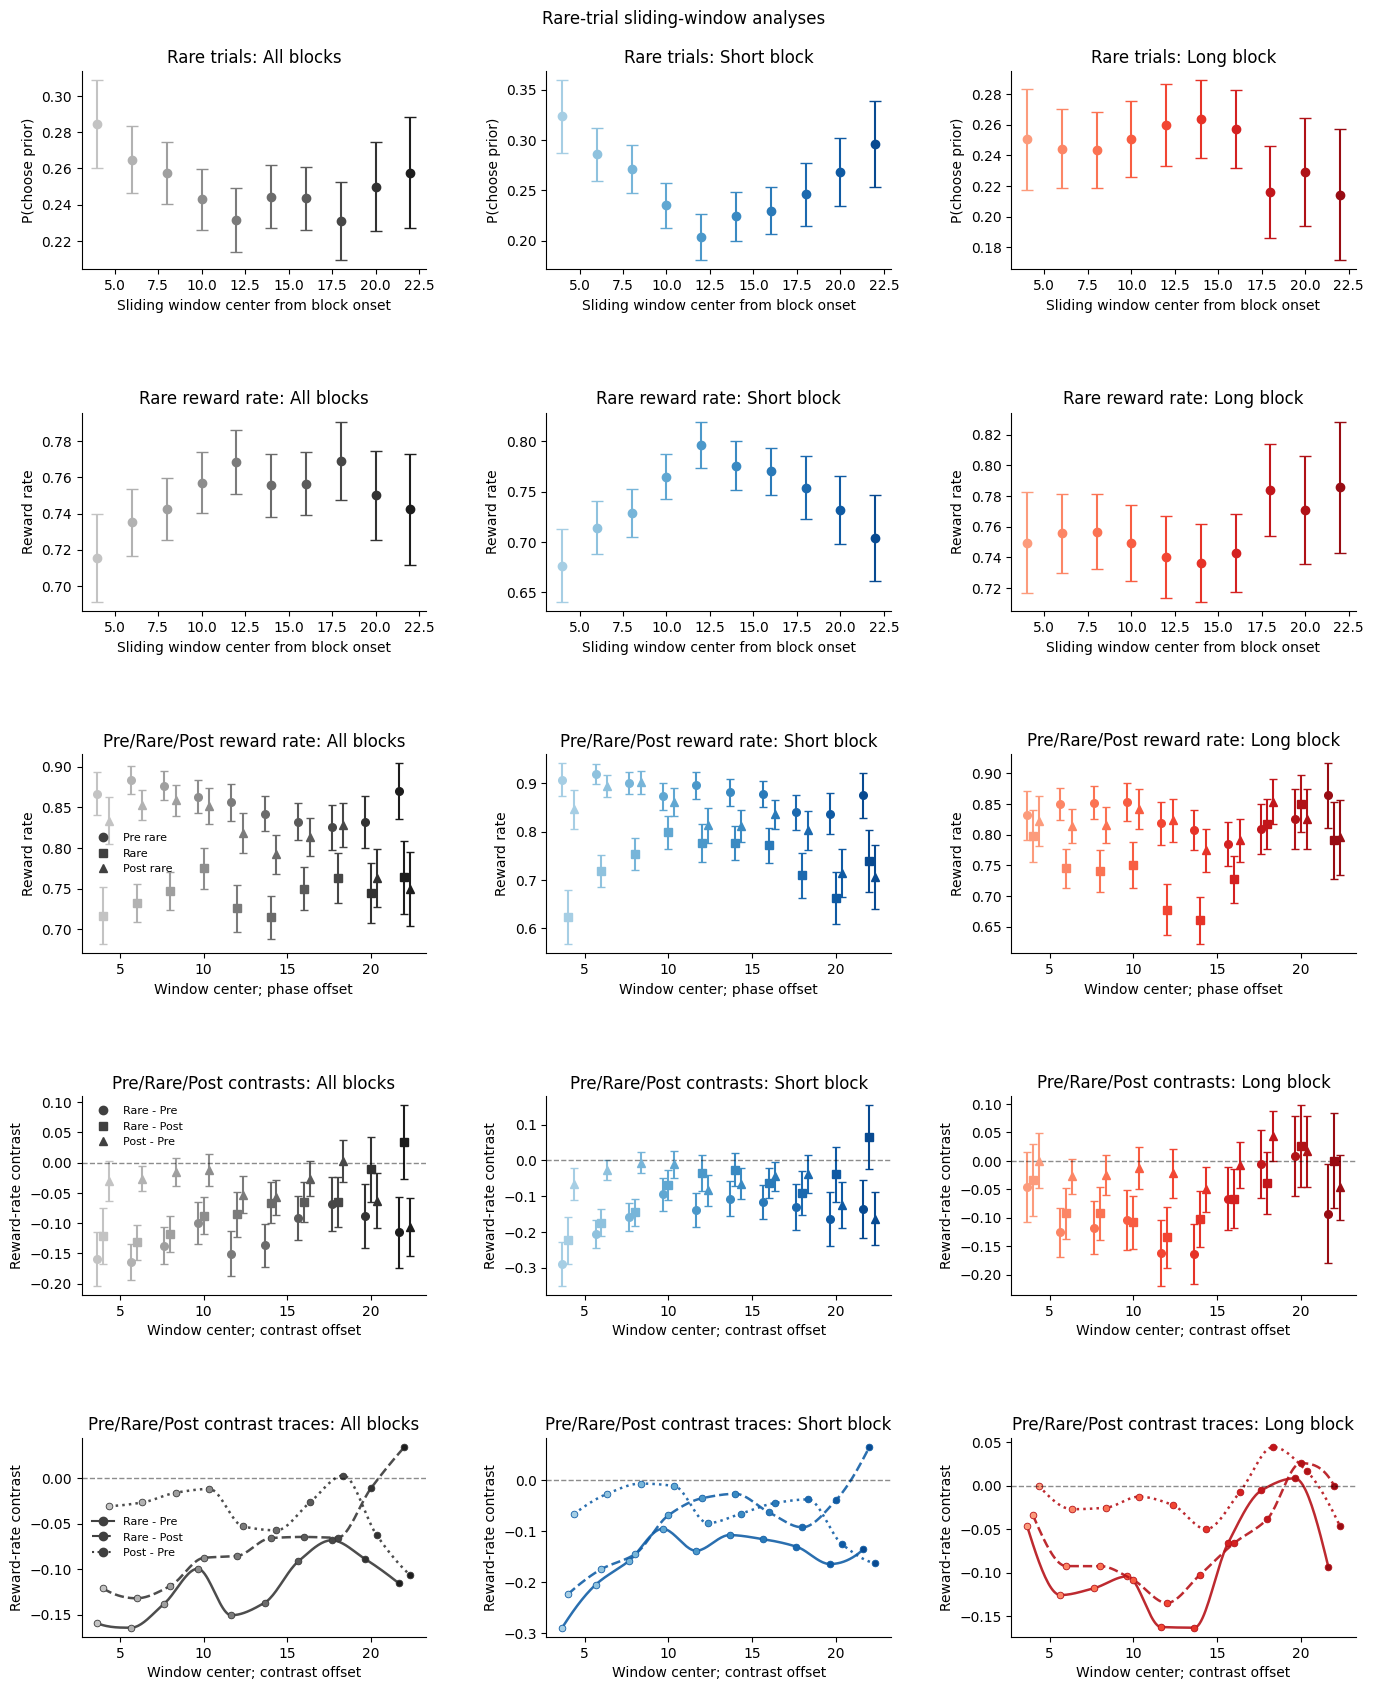

Configured block_length by session
 block_length  sessions
           20         8
           25        34

Sessions with configured block_length 25: 34

Rare trials, All blocks: P(choose prior) summary
 window_start_trial  window_end_trial  window_center_trial     mean      sem  n_windows  n_rare_trials
                  1                 7                  4.0 0.284528 0.024405        321            392
                  3                 9                  6.0 0.264896 0.018538        480            719
                  5                11                  8.0 0.257261 0.017065        482            931
                  7                13                 10.0 0.243004 0.016804        455            928
                  9                15                 12.0 0.231601 0.017760        433            811
                 11                17                 14.0 0.244444 0.017577        456            852
                 13                19                 16.0 0.243576 0.017423

In [15]:
# Sliding-window rare-trial prior choice, reward rate, and pre/rare/post reward rate
from matplotlib.lines import Line2D
from scipy.interpolate import PchipInterpolator

if "df" not in globals():
    df = prepare_dataframe(DATA_PATH)

PRIOR_WINDOW_SIZE = 7
PRIOR_WINDOW_STEP = 2
PRIOR_OUTPUT_PATH = "/home/ihsan/Desktop/data/Georgia_Tech/2AFC/Figures_behavior/Mega_pdf/rare_trial_prior_choice_sliding_window.pdf"
PRIOR_BLOCKS = [
    ("All blocks", None, "Greys"),
    ("Short block", 1, "Blues"),
    ("Long block", 2, "Reds"),
]
PHASE_MARKERS = {"pre_rare": "o", "rare": "s", "post_rare": "^"}
PHASE_OFFSETS = {"pre_rare": -0.35, "rare": 0.0, "post_rare": 0.35}
PHASE_LABEL_MAP = dict(zip(PHASE_ORDER, PHASE_LABELS))
CONTRAST_ORDER = ["rare_minus_pre", "rare_minus_post", "post_minus_pre"]
CONTRAST_LABELS = {
    "rare_minus_pre": "Rare - Pre",
    "rare_minus_post": "Rare - Post",
    "post_minus_pre": "Post - Pre",
}
CONTRAST_MARKERS = {"rare_minus_pre": "o", "rare_minus_post": "s", "post_minus_pre": "^"}
CONTRAST_OFFSETS = {"rare_minus_pre": -0.35, "rare_minus_post": 0.0, "post_minus_pre": 0.35}
CONTRAST_LINESTYLES = {"rare_minus_pre": "-", "rare_minus_post": "--", "post_minus_pre": ":"}


def add_choose_prior(data):
    data = data.copy()
    data["choose_prior"] = np.nan
    data.loc[data["block_type"].eq(1), "choose_prior"] = data.loc[
        data["block_type"].eq(1), "choose_short"
    ]
    data.loc[data["block_type"].eq(2), "choose_prior"] = data.loc[
        data["block_type"].eq(2), "choose_long"
    ]
    return data


def configured_block_length_for_block(block_df):
    observed_block_length = int(block_df["_block_length"].iloc[0])
    if "block_length" not in block_df.columns:
        return observed_block_length

    configured_values = pd.to_numeric(block_df["block_length"], errors="coerce").dropna()
    configured_values = configured_values[configured_values.gt(0)]
    if configured_values.empty:
        return observed_block_length

    return int(configured_values.iloc[0])


def analysis_block_length_for_block(block_df):
    observed_block_length = int(block_df["_block_length"].iloc[0])
    configured_block_length = configured_block_length_for_block(block_df)
    return min(observed_block_length, configured_block_length)


def sliding_window_starts(block_length, window_size=PRIOR_WINDOW_SIZE, step=PRIOR_WINDOW_STEP):
    block_length = int(block_length)
    if block_length < window_size:
        return []

    return list(range(0, block_length - window_size + 1, step))


def collect_rare_window_units(data, window_size=PRIOR_WINDOW_SIZE, step=PRIOR_WINDOW_STEP):
    require_columns(
        data,
        [
            "session_key",
            "block_instance",
            "block_type",
            "_within_block_index",
            "_block_length",
            "is_rare",
            "correct",
            "choose_long",
            "choose_short",
        ],
    )

    data = add_choose_prior(data)
    data = data[data["block_type"].isin([1, 2])].copy()
    block_labels = {1: "Short block", 2: "Long block"}
    rows = []

    for (session_key, block_instance), block_df in data.groupby(
        ["session_key", "block_instance"], sort=False
    ):
        block_df = block_df.sort_values("_within_block_index").copy()
        block_type = int(block_df["block_type"].iloc[0])
        observed_block_length = int(block_df["_block_length"].iloc[0])
        configured_block_length = configured_block_length_for_block(block_df)
        analysis_block_length = analysis_block_length_for_block(block_df)

        for window_start in sliding_window_starts(analysis_block_length, window_size, step):
            window_end = window_start + window_size - 1
            in_window = block_df["_within_block_index"].between(window_start, window_end)
            rare_trials = block_df.loc[in_window & block_df["is_rare"]].dropna(
                subset=["choose_prior", "correct"]
            )
            if rare_trials.empty:
                continue

            rows.append(
                {
                    "session_key": session_key,
                    "block_instance": block_instance,
                    "block_type": block_type,
                    "block_label": block_labels[block_type],
                    "window_start": int(window_start),
                    "window_end": int(window_end),
                    "window_center": window_start + (window_size - 1) / 2,
                    "window_start_trial": int(window_start + 1),
                    "window_end_trial": int(window_end + 1),
                    "window_center_trial": window_start + (window_size - 1) / 2 + 1,
                    "observed_block_length": observed_block_length,
                    "configured_block_length": configured_block_length,
                    "analysis_block_length": analysis_block_length,
                    "p_choose_prior": rare_trials["choose_prior"].mean(),
                    "reward_rate": rare_trials["correct"].mean(),
                    "n_rare_trials": len(rare_trials),
                }
            )

    return pd.DataFrame(rows)


def collect_pre_rare_post_window_units(data, window_size=PRIOR_WINDOW_SIZE, step=PRIOR_WINDOW_STEP):
    require_columns(
        data,
        [
            "session_key",
            "block_instance",
            "block_type",
            "_within_block_index",
            "_block_length",
            "is_rare",
            "correct",
        ],
    )

    data = data[data["block_type"].isin([1, 2])].copy()
    block_labels = {1: "Short block", 2: "Long block"}
    trial_rows = []

    for (session_key, block_instance), block_df in data.groupby(
        ["session_key", "block_instance"], sort=False
    ):
        block_df = block_df.sort_values("_within_block_index").copy()
        block_type = int(block_df["block_type"].iloc[0])
        observed_block_length = int(block_df["_block_length"].iloc[0])
        configured_block_length = configured_block_length_for_block(block_df)
        analysis_block_length = analysis_block_length_for_block(block_df)
        block_indexed = block_df.set_index("_within_block_index", drop=False)

        for window_start in sliding_window_starts(analysis_block_length, window_size, step):
            window_end = window_start + window_size - 1
            for anchor_position in range(window_start + 1, window_end):
                if anchor_position not in block_indexed.index:
                    continue

                anchor = block_indexed.loc[anchor_position]
                if not bool(anchor["is_rare"]):
                    continue

                pre_position = anchor_position - 1
                post_position = anchor_position + 1
                if pre_position not in block_indexed.index or post_position not in block_indexed.index:
                    continue
                if pre_position < window_start or post_position > window_end:
                    continue

                pre_trial = block_indexed.loc[pre_position]
                post_trial = block_indexed.loc[post_position]
                previous_position = pre_position - 1
                pre_is_after_rare = (
                    previous_position in block_indexed.index
                    and bool(block_indexed.loc[previous_position, "is_rare"])
                )
                sequence_matches_rules = (
                    not bool(pre_trial["is_rare"])
                    and not pre_is_after_rare
                    and not bool(post_trial["is_rare"])
                )
                if not sequence_matches_rules:
                    continue

                anchor_id = f"{session_key}_{block_instance}_{anchor_position}"
                for phase, phase_order, trial in [
                    ("pre_rare", 0, pre_trial),
                    ("rare", 1, anchor),
                    ("post_rare", 2, post_trial),
                ]:
                    if pd.isna(trial["correct"]):
                        continue

                    trial_rows.append(
                        {
                            "session_key": session_key,
                            "block_instance": block_instance,
                            "block_type": block_type,
                            "block_label": block_labels[block_type],
                            "anchor_id": anchor_id,
                            "anchor_position": int(anchor_position),
                            "phase": phase,
                            "phase_order": phase_order,
                            "window_start": int(window_start),
                            "window_end": int(window_end),
                            "window_center": window_start + (window_size - 1) / 2,
                            "window_start_trial": int(window_start + 1),
                            "window_end_trial": int(window_end + 1),
                            "window_center_trial": window_start + (window_size - 1) / 2 + 1,
                            "observed_block_length": observed_block_length,
                            "configured_block_length": configured_block_length,
                            "analysis_block_length": analysis_block_length,
                            "correct": trial["correct"],
                        }
                    )

    if not trial_rows:
        return pd.DataFrame()

    trial_data = pd.DataFrame(trial_rows)
    group_cols = [
        "session_key",
        "block_instance",
        "block_type",
        "block_label",
        "window_start_trial",
        "window_end_trial",
        "window_center_trial",
        "phase",
        "phase_order",
    ]
    return (
        trial_data.groupby(group_cols)["correct"]
        .agg(reward_rate="mean", n_trials="count")
        .reset_index()
    )


def summarize_rare_windows(window_units, metric, block_type=None):
    columns = [
        "window_start_trial",
        "window_end_trial",
        "window_center_trial",
        "mean",
        "sem",
        "n_windows",
        "n_rare_trials",
    ]
    if window_units.empty:
        return pd.DataFrame(columns=columns)

    data = window_units.copy()
    if block_type is not None:
        data = data[data["block_type"].eq(block_type)].copy()
    if data.empty:
        return pd.DataFrame(columns=columns)

    group_cols = [
        "window_start_trial",
        "window_end_trial",
        "window_center_trial",
    ]
    summary = (
        data.groupby(group_cols)[metric]
        .agg(mean="mean", sem="sem", n_windows="count")
        .reset_index()
    )
    counts = data.groupby(group_cols)["n_rare_trials"].sum().reset_index()
    summary = summary.merge(counts, on=group_cols, how="left")
    summary.loc[summary["n_windows"].le(1), "sem"] = 0.0
    return summary[columns].sort_values("window_center_trial")


def summarize_phase_windows(phase_window_units, block_type=None):
    columns = [
        "window_start_trial",
        "window_end_trial",
        "window_center_trial",
        "phase",
        "phase_order",
        "mean",
        "sem",
        "n_windows",
        "n_trials",
    ]
    if phase_window_units.empty:
        return pd.DataFrame(columns=columns)

    data = phase_window_units.copy()
    if block_type is not None:
        data = data[data["block_type"].eq(block_type)].copy()
    if data.empty:
        return pd.DataFrame(columns=columns)

    group_cols = [
        "window_start_trial",
        "window_end_trial",
        "window_center_trial",
        "phase",
        "phase_order",
    ]
    summary = (
        data.groupby(group_cols)["reward_rate"]
        .agg(mean="mean", sem="sem", n_windows="count")
        .reset_index()
    )
    counts = data.groupby(group_cols)["n_trials"].sum().reset_index()
    summary = summary.merge(counts, on=group_cols, how="left")
    summary.loc[summary["n_windows"].le(1), "sem"] = 0.0
    return summary[columns].sort_values(["window_center_trial", "phase_order"])


def summarize_phase_contrast_windows(phase_window_units, block_type=None):
    columns = [
        "window_start_trial",
        "window_end_trial",
        "window_center_trial",
        "contrast",
        "contrast_order",
        "mean",
        "sem",
        "n_windows",
    ]
    if phase_window_units.empty:
        return pd.DataFrame(columns=columns)

    data = phase_window_units.copy()
    if block_type is not None:
        data = data[data["block_type"].eq(block_type)].copy()
    if data.empty:
        return pd.DataFrame(columns=columns)

    index_cols = [
        "session_key",
        "block_instance",
        "block_type",
        "block_label",
        "window_start_trial",
        "window_end_trial",
        "window_center_trial",
    ]
    wide = data.pivot_table(
        index=index_cols,
        columns="phase",
        values="reward_rate",
        aggfunc="mean",
    ).reset_index()

    contrast_specs = [
        ("rare_minus_pre", "rare", "pre_rare", 0),
        ("rare_minus_post", "rare", "post_rare", 1),
        ("post_minus_pre", "post_rare", "pre_rare", 2),
    ]
    contrast_rows = []
    for contrast, left_phase, right_phase, contrast_order in contrast_specs:
        if left_phase not in wide.columns or right_phase not in wide.columns:
            continue

        contrast_data = wide.dropna(subset=[left_phase, right_phase]).copy()
        if contrast_data.empty:
            continue

        contrast_data["contrast_value"] = contrast_data[left_phase] - contrast_data[right_phase]
        contrast_data["contrast"] = contrast
        contrast_data["contrast_order"] = contrast_order
        contrast_rows.append(
            contrast_data[
                [
                    "window_start_trial",
                    "window_end_trial",
                    "window_center_trial",
                    "contrast",
                    "contrast_order",
                    "contrast_value",
                ]
            ]
        )

    if not contrast_rows:
        return pd.DataFrame(columns=columns)

    contrast_data = pd.concat(contrast_rows, ignore_index=True)
    group_cols = [
        "window_start_trial",
        "window_end_trial",
        "window_center_trial",
        "contrast",
        "contrast_order",
    ]
    summary = (
        contrast_data.groupby(group_cols)["contrast_value"]
        .agg(mean="mean", sem="sem", n_windows="count")
        .reset_index()
    )
    summary.loc[summary["n_windows"].le(1), "sem"] = 0.0
    return summary[columns].sort_values(["window_center_trial", "contrast_order"])


def window_colors(valid, cmap_name):
    cmap = plt.get_cmap(cmap_name)
    unique_centers = np.array(sorted(valid["window_center_trial"].dropna().unique()))
    if len(unique_centers) == 0:
        return {}
    color_values = np.linspace(0.35, 0.9, len(unique_centers))
    return dict(zip(unique_centers, [cmap(value) for value in color_values]))


def plot_metric_windows(ax, summary, title, ylabel, cmap_name):
    valid = summary.dropna(subset=["mean"]).copy()
    if valid.empty:
        ax.text(0.5, 0.5, "No rare trials", transform=ax.transAxes, ha="center", va="center")
    else:
        colors = window_colors(valid, cmap_name)
        for _, row in valid.iterrows():
            color = colors[row["window_center_trial"]]
            ax.errorbar(
                row["window_center_trial"],
                row["mean"],
                yerr=row["sem"],
                fmt="o",
                linestyle="none",
                markersize=6,
                capsize=4,
                color=color,
                ecolor=color,
            )

    ax.set_title(title)
    ax.set_xlabel("Sliding window center from block onset")
    ax.set_ylabel(ylabel)
    clean_axis(ax)


def plot_phase_windows(ax, summary, title, cmap_name, show_legend=False):
    valid = summary.dropna(subset=["mean"]).copy()
    if valid.empty:
        ax.text(0.5, 0.5, "No complete triplets", transform=ax.transAxes, ha="center", va="center")
    else:
        colors = window_colors(valid, cmap_name)
        for phase in PHASE_ORDER:
            phase_data = valid[valid["phase"].eq(phase)].copy()
            for _, row in phase_data.iterrows():
                color = colors[row["window_center_trial"]]
                ax.errorbar(
                    row["window_center_trial"] + PHASE_OFFSETS[phase],
                    row["mean"],
                    yerr=row["sem"],
                    fmt=PHASE_MARKERS[phase],
                    linestyle="none",
                    markersize=5.5,
                    capsize=3,
                    color=color,
                    ecolor=color,
                )

    ax.set_title(title)
    ax.set_xlabel("Window center; phase offset")
    ax.set_ylabel("Reward rate")
    if show_legend and not valid.empty:
        handles = [
            Line2D(
                [0],
                [0],
                marker=PHASE_MARKERS[phase],
                color="0.25",
                linestyle="none",
                label=PHASE_LABEL_MAP[phase],
            )
            for phase in PHASE_ORDER
        ]
        ax.legend(handles=handles, frameon=False, fontsize=8)
    clean_axis(ax)


def plot_contrast_windows(ax, summary, title, cmap_name, show_legend=False):
    valid = summary.dropna(subset=["mean"]).copy()
    if valid.empty:
        ax.text(0.5, 0.5, "No paired contrasts", transform=ax.transAxes, ha="center", va="center")
    else:
        colors = window_colors(valid, cmap_name)
        for contrast in CONTRAST_ORDER:
            contrast_data = valid[valid["contrast"].eq(contrast)].copy()
            for _, row in contrast_data.iterrows():
                color = colors[row["window_center_trial"]]
                ax.errorbar(
                    row["window_center_trial"] + CONTRAST_OFFSETS[contrast],
                    row["mean"],
                    yerr=row["sem"],
                    fmt=CONTRAST_MARKERS[contrast],
                    linestyle="none",
                    markersize=5.5,
                    capsize=3,
                    color=color,
                    ecolor=color,
                )

    ax.axhline(0, color="black", linestyle="--", linewidth=1, alpha=0.45)
    ax.set_title(title)
    ax.set_xlabel("Window center; contrast offset")
    ax.set_ylabel("Reward-rate contrast")
    if show_legend and not valid.empty:
        handles = [
            Line2D(
                [0],
                [0],
                marker=CONTRAST_MARKERS[contrast],
                color="0.25",
                linestyle="none",
                label=CONTRAST_LABELS[contrast],
            )
            for contrast in CONTRAST_ORDER
        ]
        ax.legend(handles=handles, frameon=False, fontsize=8)
    clean_axis(ax)


def smoothed_trace_points(x, y, n_points=200):
    trace = pd.DataFrame({"x": x, "y": y}).replace([np.inf, -np.inf], np.nan).dropna()
    trace = trace.groupby("x", as_index=False)["y"].mean().sort_values("x")
    if len(trace) < 3:
        return trace["x"].to_numpy(), trace["y"].to_numpy()

    smooth_x = np.linspace(trace["x"].min(), trace["x"].max(), n_points)
    smooth_y = PchipInterpolator(trace["x"].to_numpy(), trace["y"].to_numpy())(smooth_x)
    return smooth_x, smooth_y


def plot_contrast_trace_windows(ax, summary, title, cmap_name, show_legend=False):
    valid = summary.dropna(subset=["mean"]).copy()
    if valid.empty:
        ax.text(0.5, 0.5, "No paired contrasts", transform=ax.transAxes, ha="center", va="center")
    else:
        colors = window_colors(valid, cmap_name)
        trace_color = plt.get_cmap(cmap_name)(0.82)
        for contrast in CONTRAST_ORDER:
            contrast_data = valid[valid["contrast"].eq(contrast)].sort_values("window_center_trial")
            if contrast_data.empty:
                continue

            x = contrast_data["window_center_trial"].to_numpy() + CONTRAST_OFFSETS[contrast]
            y = contrast_data["mean"].to_numpy()
            smooth_x, smooth_y = smoothed_trace_points(x, y)
            ax.plot(
                smooth_x,
                smooth_y,
                color=trace_color,
                linestyle=CONTRAST_LINESTYLES[contrast],
                linewidth=1.8,
                alpha=0.9,
            )
            for _, row in contrast_data.iterrows():
                color = colors[row["window_center_trial"]]
                ax.plot(
                    row["window_center_trial"] + CONTRAST_OFFSETS[contrast],
                    row["mean"],
                    marker="o",
                    linestyle="none",
                    markersize=4.8,
                    color=color,
                    markeredgecolor=trace_color,
                    markeredgewidth=0.6,
                )

    ax.axhline(0, color="black", linestyle="--", linewidth=1, alpha=0.45)
    ax.set_title(title)
    ax.set_xlabel("Window center; contrast offset")
    ax.set_ylabel("Reward-rate contrast")
    if show_legend and not valid.empty:
        handles = [
            Line2D(
                [0],
                [0],
                color="0.25",
                linestyle=CONTRAST_LINESTYLES[contrast],
                marker="o",
                label=CONTRAST_LABELS[contrast],
            )
            for contrast in CONTRAST_ORDER
        ]
        ax.legend(handles=handles, frameon=False, fontsize=8)
    clean_axis(ax)


def summarize_configured_block_lengths(data):
    if "block_length" not in data.columns:
        return pd.DataFrame(columns=["block_length", "sessions"])

    session_lengths = data[["session_key", "block_length"]].drop_duplicates().copy()
    session_lengths["block_length"] = pd.to_numeric(session_lengths["block_length"], errors="coerce")
    session_lengths = session_lengths.dropna(subset=["block_length"])
    session_lengths["block_length"] = session_lengths["block_length"].astype(int)
    return (
        session_lengths.groupby("block_length")["session_key"]
        .nunique()
        .rename("sessions")
        .reset_index()
        .sort_values("block_length")
    )


def make_rare_prior_choice_figure(data):
    rare_window_units = collect_rare_window_units(data)
    phase_window_units = collect_pre_rare_post_window_units(data)
    summaries = {}

    for block_label, block_type, _ in PRIOR_BLOCKS:
        summaries[("prior", block_label)] = summarize_rare_windows(
            rare_window_units,
            metric="p_choose_prior",
            block_type=block_type,
        )
        summaries[("rare_reward", block_label)] = summarize_rare_windows(
            rare_window_units,
            metric="reward_rate",
            block_type=block_type,
        )
        summaries[("phase_reward", block_label)] = summarize_phase_windows(
            phase_window_units,
            block_type=block_type,
        )
        summaries[("phase_contrast", block_label)] = summarize_phase_contrast_windows(
            phase_window_units,
            block_type=block_type,
        )

    fig = plt.figure(figsize=(14, 17.4))
    gs = gridspec.GridSpec(5, len(PRIOR_BLOCKS), figure=fig, wspace=0.35, hspace=0.72)
    axes = {}

    for col_idx, (block_label, _, cmap_name) in enumerate(PRIOR_BLOCKS):
        ax = fig.add_subplot(gs[0, col_idx])
        plot_metric_windows(
            ax,
            summaries[("prior", block_label)],
            f"Rare trials: {block_label}",
            "P(choose prior)",
            cmap_name,
        )
        axes[("prior", block_label)] = ax

        ax = fig.add_subplot(gs[1, col_idx])
        plot_metric_windows(
            ax,
            summaries[("rare_reward", block_label)],
            f"Rare reward rate: {block_label}",
            "Reward rate",
            cmap_name,
        )
        axes[("rare_reward", block_label)] = ax

        ax = fig.add_subplot(gs[2, col_idx])
        plot_phase_windows(
            ax,
            summaries[("phase_reward", block_label)],
            f"Pre/Rare/Post reward rate: {block_label}",
            cmap_name,
            show_legend=(col_idx == 0),
        )
        axes[("phase_reward", block_label)] = ax

        ax = fig.add_subplot(gs[3, col_idx])
        plot_contrast_windows(
            ax,
            summaries[("phase_contrast", block_label)],
            f"Pre/Rare/Post contrasts: {block_label}",
            cmap_name,
            show_legend=(col_idx == 0),
        )
        axes[("phase_contrast", block_label)] = ax

        ax = fig.add_subplot(gs[4, col_idx])
        plot_contrast_trace_windows(
            ax,
            summaries[("phase_contrast", block_label)],
            f"Pre/Rare/Post contrast traces: {block_label}",
            cmap_name,
            show_legend=(col_idx == 0),
        )
        axes[("phase_contrast_trace", block_label)] = ax

    fig.suptitle("Rare-trial sliding-window analyses", y=0.99)
    fig.subplots_adjust(left=0.07, right=0.98, bottom=0.055, top=0.955)
    return {
        "fig": fig,
        "axes": axes,
        "rare_window_units": rare_window_units,
        "phase_window_units": phase_window_units,
        "summary": summaries,
    }


rare_prior_result = make_rare_prior_choice_figure(df)
rare_prior_result["fig"].savefig(PRIOR_OUTPUT_PATH, dpi=600, bbox_inches="tight")
plt.show()

block_length_summary = summarize_configured_block_lengths(df)
print("Configured block_length by session")
print(block_length_summary.to_string(index=False))
if not block_length_summary.empty:
    n_block_length_25 = block_length_summary.loc[
        block_length_summary["block_length"].eq(25), "sessions"
    ].sum()
    print(f"\nSessions with configured block_length 25: {int(n_block_length_25)}")

for block_label, _, _ in PRIOR_BLOCKS:
    print(f"\nRare trials, {block_label}: P(choose prior) summary")
    print(rare_prior_result["summary"][("prior", block_label)].to_string(index=False))
    print(f"\nRare trials, {block_label}: reward-rate summary")
    print(rare_prior_result["summary"][("rare_reward", block_label)].to_string(index=False))
    print(f"\nPre/Rare/Post, {block_label}: reward-rate summary")
    print(rare_prior_result["summary"][("phase_reward", block_label)].to_string(index=False))
    print(f"\nPre/Rare/Post, {block_label}: reward-rate contrast summary")
    print(rare_prior_result["summary"][("phase_contrast", block_label)].to_string(index=False))


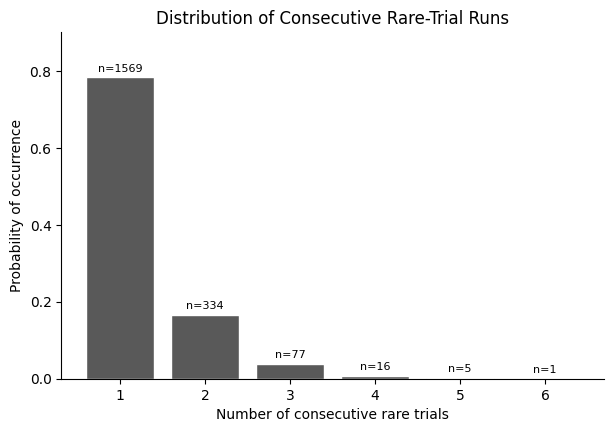

Consecutive rare-trial run distribution
 run_length  count  probability
          1   1569     0.783716
          2    334     0.166833
          3     77     0.038462
          4     16     0.007992
          5      5     0.002498
          6      1     0.000500

By block type
block_label  run_length  count  probability
 Long block           1    777     0.779338
 Long block           2    165     0.165496
 Long block           3     42     0.042126
 Long block           4     11     0.011033
 Long block           5      1     0.001003
 Long block           6      1     0.001003
Short block           1    792     0.788060
Short block           2    169     0.168159
Short block           3     35     0.034826
Short block           4      5     0.004975
Short block           5      4     0.003980


In [16]:
# Distribution of consecutive rare-trial runs within each block
if "df" not in globals():
    df = prepare_dataframe(DATA_PATH)


def collect_consecutive_rare_runs(df):
    rows = []
    block_labels = {1: "Short block", 2: "Long block"}

    for (session_key, block_instance), block_df in df.groupby(
        ["session_key", "block_instance"], sort=False
    ):
        block_df = block_df.sort_values("_within_block_index")
        rare_flags = block_df["is_rare"].to_numpy(dtype=bool)
        if not rare_flags.any():
            continue

        run_changes = np.diff(np.r_[False, rare_flags, False].astype(int))
        run_starts = np.flatnonzero(run_changes == 1)
        run_ends = np.flatnonzero(run_changes == -1)
        block_type = int(block_df["block_type"].iloc[0])

        for run_start, run_end in zip(run_starts, run_ends):
            rows.append(
                {
                    "session_key": session_key,
                    "block_instance": block_instance,
                    "block_type": block_type,
                    "block_label": block_labels.get(block_type, f"Block type {block_type}"),
                    "run_start_within_block": int(run_start),
                    "run_end_within_block": int(run_end - 1),
                    "run_length": int(run_end - run_start),
                }
            )

    return pd.DataFrame(rows)


rare_run_lengths = collect_consecutive_rare_runs(df)

if rare_run_lengths.empty:
    print("No rare-trial runs found.")
else:
    rare_run_distribution = (
        rare_run_lengths.groupby("run_length")
        .size()
        .rename("count")
        .reset_index()
        .sort_values("run_length")
    )
    rare_run_distribution["probability"] = (
        rare_run_distribution["count"] / rare_run_distribution["count"].sum()
    )

    rare_run_distribution_by_block = (
        rare_run_lengths.groupby(["block_label", "run_length"])
        .size()
        .rename("count")
        .reset_index()
        .sort_values(["block_label", "run_length"])
    )
    rare_run_distribution_by_block["probability"] = rare_run_distribution_by_block.groupby(
        "block_label"
    )["count"].transform(lambda counts: counts / counts.sum())

    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.bar(
        rare_run_distribution["run_length"],
        rare_run_distribution["probability"],
        color="0.35",
        edgecolor="white",
        linewidth=1.0,
    )

    ax.set_title("Distribution of Consecutive Rare-Trial Runs")
    ax.set_xlabel("Number of consecutive rare trials")
    ax.set_ylabel("Probability of occurrence")
    ax.set_xticks(rare_run_distribution["run_length"])
    ax.set_ylim(0, max(0.05, rare_run_distribution["probability"].max() * 1.15))
    clean_axis(ax)

    for _, row in rare_run_distribution.iterrows():
        ax.text(
            row["run_length"],
            row["probability"] + 0.01,
            f"n={int(row['count'])}",
            ha="center",
            va="bottom",
            fontsize=8,
        )

    fig.savefig("/home/ihsan/Desktop/data/Georgia_Tech/2AFC/Figures_behavior/Mega_pdf/consecutive_rare_trial_run_distribution.pdf", dpi=600, bbox_inches="tight")
    plt.show()

    print("Consecutive rare-trial run distribution")
    print(rare_run_distribution.to_string(index=False))
    print("\nBy block type")
    print(rare_run_distribution_by_block.to_string(index=False))
